# Finetuning the Pre-trained EfficientNet B0 Model to Perform Image Classification for CUB_200_2011

This notebook attempts to fine-tune an EfficientNet B0 model to classify the 200 species of birds from their cropped images. It makes use of the preprocessing done by `notebooks/imagePrep.ipynb`, `scripts/prepare_images.py`, `notebooks/05_image_preparation.ipynb`, `scripts/augmentation.py`. As such, those files must be run in that order beforehand.

Some of the code has been inspired from the tutorial by [Fu (2026)](https://keras.io/examples/vision/image_classification_efficientnet_fine_tuning/). This has been marked in the appropriate places.

Table of Contents
1. Understanding our Data
2. Sourcing Image Data
3. Building the Model
4. Fine-tuning

In [16]:
# Setting constants to be used later
IMG_SIZE=224 # The width and height of the images
NUM_CLASSES=200 # The number of bird classes

## Section 1: Understanding our Data

Viewing the processed `cub_images_cropped.csv`.

In [17]:
import pandas as pd
img_data = pd.read_csv("../data/processed/cub_images_cropped.csv")

img_data.head()

,image_id,image_path,class_id,species,is_train,bbox_x,bbox_y,bbox_w,bbox_h,bbox_clipped,width,height,mode,cropped_path
0,1,001.Black_footed_Albatross/Black_Footed_Albatr...,1,Black footed Albatross,0,60.0,27.0,325.0,304.0,0,500,335,RGB,images_cropped/001.Black_footed_Albatross/Blac...
1,2,001.Black_footed_Albatross/Black_Footed_Albatr...,1,Black footed Albatross,1,139.0,30.0,153.0,264.0,0,500,336,RGB,images_cropped/001.Black_footed_Albatross/Blac...
2,3,001.Black_footed_Albatross/Black_Footed_Albatr...,1,Black footed Albatross,0,14.0,112.0,388.0,186.0,0,500,347,RGB,images_cropped/001.Black_footed_Albatross/Blac...
3,4,001.Black_footed_Albatross/Black_Footed_Albatr...,1,Black footed Albatross,1,112.0,90.0,255.0,242.0,0,415,500,RGB,images_cropped/001.Black_footed_Albatross/Blac...
4,5,001.Black_footed_Albatross/Black_Footed_Albatr...,1,Black footed Albatross,1,70.0,50.0,134.0,303.0,0,331,380,RGB,images_cropped/001.Black_footed_Albatross/Blac...


# Section 2: Sourcing Image Data

Instead of reworking the image loading logic that has already been coded in other files, this file will borrow their methods. Specifically, the following method adapts the image loading logic used in `notebooks/resnet50_altered_224px.ipynb` written by David Ling Jia Hao.

A separate function is made to convert from the PyTorch style loaders to more Tensorflow loaders. Tensorflow has been chosen for ease of use and familiarity as it was used during the lab sessions.

In [31]:
# The following code has been inspired by Claude
# It was given other files in this repo to figure out how to leverage them to load images
# Access that conversation here: https://claude.ai/share/fc7c1406-a1ea-49a5-9ec3-177e718d355e
# resnet50_altered_224px.ipynb was heavily referenced too.
# Despite the referencing, all code has been retyped by hand
# and edited in some places where required/desired by myself (Suhaib).

import sys
sys.path.insert(0, "../scripts")

import tensorflow as tf
from augmentation import make_loaders

train_dl, val_dl, test_dl = make_loaders("../data/processed", normalise=False)

# Getting a TF dataset (numpy) using David's loaders from PyTorch
def to_tf(loader):
    def gen():
        for x, y in loader:
            yield x.permute(0, 2, 3, 1).numpy() * 255.0, y.numpy()

    return tf.data.Dataset.from_generator(
        gen,
        output_signature=(tf.TensorSpec((None, IMG_SIZE, IMG_SIZE, 3), tf.float32),
                          tf.TensorSpec((None,), tf.int64))
    ).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = to_tf(train_dl), to_tf(val_dl), to_tf(test_dl)

print(train_ds)

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>


## Section 3: Building the Model

The following function has been inspired by [Fu (2026)](https://keras.io/examples/vision/image_classification_efficientnet_fine_tuning/) to build the fine-tuned model's architecture.

In [23]:
from keras.applications import EfficientNetB0
from keras import layers, Model, optimizers, metrics

def build_model(top_dropout_rate, learning_rate):
    # Initialise pre-trained model
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    model = EfficientNetB0(include_top=False, input_tensor=inputs, weights="imagenet")

    # Freeze pretrained weights
    model.trainable = False

    x = layers.GlobalAveragePooling2D(name="avg_pool")(model.output)
    x = layers.BatchNormalization()(x)

    x = layers.Dropout(top_dropout_rate, name="top_dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="pred")(x)

    # Compile
    model = Model(inputs, outputs, name="EfficientNet")
    model.compile(
        optimizer = optimizers.Adam(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy", metrics.F1Score(average="macro", name="macro_f1")]
    )

    return model


The following function has been inspired by [Fu (2026)](https://keras.io/examples/vision/image_classification_efficientnet_fine_tuning/) to plot historgrams.

In [24]:
# Function to visualise histogram after training
import matplotlib.pyplot as plt

def plot_hist(hist):
    plt.plot(hist.history["accuracy"], label="train accuracy")
    plt.plot(hist.history["val_accuracy"], label="val accuracy")
    plt.plot(hist.history["macro_f1"], label="train macro_f1")
    plt.plot(hist.history["val_macro_f1"], label="val macro_f1")
    plt.title("model accuracy")
    plt.ylabel("accuracy")
    plt.xlabel("epoch")
    plt.legend(loc="upper left")
    plt.show()

# Section 4: Finetuning

Epoch 1/25


c:\Users\suhai\.conda\envs\f21dl-coursework-3.12\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


    149/Unknown 214s 951ms/step - accuracy: 0.3656 - loss: 4.3354

c:\Users\suhai\.conda\envs\f21dl-coursework-3.12\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


149/149 ━━━━━━━━━━━━━━━━━━━━ 295s 2s/step - accuracy: 0.3656 - loss: 4.3354 - val_accuracy: 0.5530 - val_loss: 1.7836
Epoch 2/25
149/149 ━━━━━━━━━━━━━━━━━━━━ 232s 1s/step - accuracy: 0.6523 - loss: 1.7040 - val_accuracy: 0.6230 - val_loss: 1.6265
Epoch 3/25
149/149 ━━━━━━━━━━━━━━━━━━━━ 234s 1s/step - accuracy: 0.7198 - loss: 1.1704 - val_accuracy: 0.6305 - val_loss: 1.6690
Epoch 4/25
149/149 ━━━━━━━━━━━━━━━━━━━━ 246s 1s/step - accuracy: 0.7691 - loss: 0.9000 - val_accuracy: 0.6530 - val_loss: 1.5689
Epoch 5/25
149/149 ━━━━━━━━━━━━━━━━━━━━ 246s 1s/step - accuracy: 0.7867 - loss: 0.8163 - val_accuracy: 0.6639 - val_loss: 1.6684
Epoch 6/25
149/149 ━━━━━━━━━━━━━━━━━━━━ 226s 1s/step - accuracy: 0.7991 - loss: 0.7556 - val_accuracy: 0.6564 - val_loss: 1.6048
Epoch 7/25
149/149 ━━━━━━━━━━━━━━━━━━━━ 162s 972ms/step - accuracy: 0.8066 - loss: 0.7287 - val_accuracy: 0.6606 - val_loss: 1.6089
Epoch 8/25
149/149 ━━━━━━━━━━━━━━━━━━━━ 159s 957ms/step - accuracy: 0.8291 - loss: 0.6475 - val_accuracy:

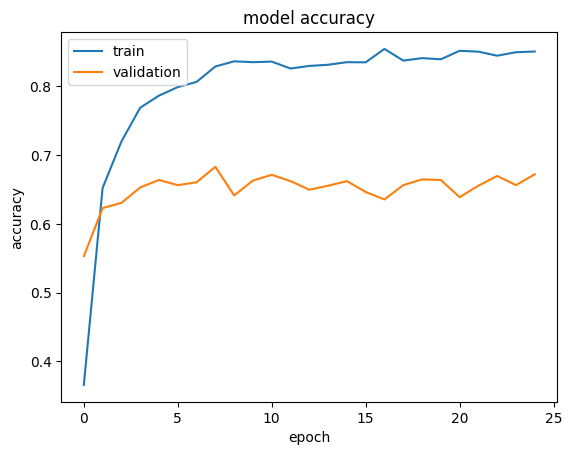

In [ ]:
# Get model
model = build_model(0.2, 1e-2)
epochs = 25

# After a laptop crash, it was deemed necessary to log backups.
# The following code has been offered by Claude after the prompt:
#   If my vscode closes and I restart the training, does it continue from where it stopped?
#   If not, is there a way to make it do that?
from keras import callbacks
backup = callbacks.BackupAndRestore(backup_dir="./checkpoints/effnet_backup")
log = callbacks.CSVLogger("./checkpoints/effnet_history.csv", append=True)
best = callbacks.ModelCheckpoint("./checkpoints/effnet_best.keras",
                                 monitor="val_accuracy", save_best_only=True)


# To allow f1_scores to be used
def one_hot(ds):
    return ds.map(lambda x, y: (x, tf.one_hot(y, NUM_CLASSES)))

hist = model.fit(
    one_hot(train_ds),
    epochs=epochs,
    validation_data=one_hot(val_ds),
    callbacks=[backup, log, best]
)
plot_hist(hist)

In [ ]:
# The following testing code has been taken from Claude (lightly edited).
# Claude was asked to explain how to test the model given our test_ds is
# a generator and not the entire dataset loaded into memory itself.

import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from keras.models import load_model
from keras import Model

# Load the best model (if using ModelCheckpoint in previous cell)
print("== Loading Best Model ==")
model: Model = load_model("./checkpoints/effnet_best.keras") # type: ignore
print("=> Loaded Best Model\n")

y_preds, y_true = [], []
for x, y in test_ds:
    y_preds.append(model.predict_on_batch(x))
    y_true.append(np.array(y))
y_preds = np.concatenate(y_preds).argmax(1)
y_true = np.concatenate(y_true)

print(f"=> Model accuracy (test set): {accuracy_score(y_true, y_preds) * 100:.4f}%")
print(f"=> Model accuracy (test set): {f1_score(y_true, y_preds, average="macro"):.4f}")

== Loading Best Model ==
=> Loaded Best Model

== Predicting on Test Set ==
=> Model accuracy (test set): 68.1222%
=> Model accuracy (test set): 0.6811


The above model seems to be overfitting and the accuracy on the validation and test sets is less than ideal, so let us try to lower the learning rate and increase the dropout rate to help the model generalise better. We also reduce the number of epochs since the previous training revealed that there wasn't much improvement after the 10th epoch. Finally, we also add the macro f1 score as a metric to be recorded (this change is made in build_model()).

c:\Users\suhai\.conda\envs\f21dl-coursework-3.12\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 2/10
    149/Unknown 136s 710ms/step - accuracy: 0.5665 - loss: 1.6609 - macro_f1: 0.5622

c:\Users\suhai\.conda\envs\f21dl-coursework-3.12\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


149/149 ━━━━━━━━━━━━━━━━━━━━ 194s 1s/step - accuracy: 0.5665 - loss: 1.6609 - macro_f1: 0.5622 - val_accuracy: 0.6297 - val_loss: 1.5394 - val_macro_f1: 0.6171
Epoch 3/10
149/149 ━━━━━━━━━━━━━━━━━━━━ 164s 976ms/step - accuracy: 0.7016 - loss: 1.1355 - macro_f1: 0.6997 - val_accuracy: 0.6639 - val_loss: 1.2424 - val_macro_f1: 0.6553
Epoch 4/10
149/149 ━━━━━━━━━━━━━━━━━━━━ 174s 1s/step - accuracy: 0.7416 - loss: 0.9336 - macro_f1: 0.7410 - val_accuracy: 0.6864 - val_loss: 1.1818 - val_macro_f1: 0.6743
Epoch 5/10
149/149 ━━━━━━━━━━━━━━━━━━━━ 177s 946ms/step - accuracy: 0.7787 - loss: 0.7827 - macro_f1: 0.7781 - val_accuracy: 0.6947 - val_loss: 1.1423 - val_macro_f1: 0.6885
Epoch 6/10
149/149 ━━━━━━━━━━━━━━━━━━━━ 157s 928ms/step - accuracy: 0.8058 - loss: 0.6778 - macro_f1: 0.8047 - val_accuracy: 0.6997 - val_loss: 1.1078 - val_macro_f1: 0.6923
Epoch 7/10
149/149 ━━━━━━━━━━━━━━━━━━━━ 161s 955ms/step - accuracy: 0.8284 - loss: 0.6152 - macro_f1: 0.8284 - val_accuracy: 0.7031 - val_loss: 1.1

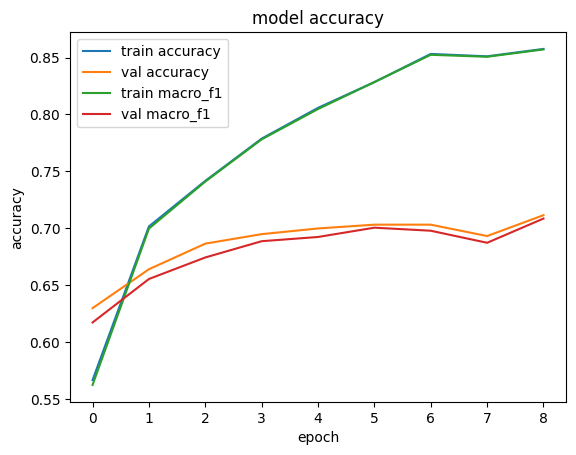

In [ ]:
# Get model
model = build_model(0.3, 1e-3)
epochs = 15

# After a laptop crash, it was deemed necessary to log backups.
# The following code has been offered by Claude after the prompt:
#   If my vscode closes and I restart the training, does it continue from where it stopped?
#   If not, is there a way to make it do that?
from keras import callbacks
backup = callbacks.BackupAndRestore(backup_dir="./checkpoints/effnet_backup")
log = callbacks.CSVLogger("./checkpoints/effnet_history.csv", append=True)
best = callbacks.ModelCheckpoint("./checkpoints/effnet_best.keras",
                                 monitor="val_accuracy", save_best_only=True)


# To allow f1_scores to be used
def one_hot(ds):
    return ds.map(lambda x, y: (x, tf.one_hot(y, NUM_CLASSES)))

hist = model.fit(
    one_hot(train_ds),
    epochs=epochs,
    validation_data=one_hot(val_ds),
    callbacks=[backup, log, best]
)

plot_hist(hist)

In [26]:
# The following testing code has been taken from Claude (lightly edited).
# Claude was asked to explain how to test the model given our test_ds is
# a generator and not the entire dataset loaded into memory itself.

import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from keras.models import load_model
from keras import Model

# Load the best model (if using ModelCheckpoint in previous cell)
print("== Loading Best Model ==")
model: Model = load_model("./checkpoints/effnet_best.keras") # type: ignore
print("=> Loaded Best Model\n")

y_preds, y_true = [], []
for x, y in test_ds:
    y_preds.append(model.predict_on_batch(x))
    y_true.append(np.array(y))
y_preds = np.concatenate(y_preds).argmax(1)
y_true = np.concatenate(y_true)

print(f"=> Model accuracy (test set): {accuracy_score(y_true, y_preds) * 100:.4f}%")
print(f"=> Model accuracy (test set): {f1_score(y_true, y_preds, average="macro"):.4f}")

== Loading Best Model ==
=> Loaded Best Model

=> Model accuracy (test set): 72.4888%
=> Model accuracy (test set): 0.7239


It seems the model accuracy has improved. Let's retry with a higher dropout rate for a higher number of epochs.

Epoch 1/20


c:\Users\suhai\.conda\envs\f21dl-coursework-3.12\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


    149/Unknown 136s 687ms/step - accuracy: 0.1999 - loss: 3.9269 - macro_f1: 0.1963

c:\Users\suhai\.conda\envs\f21dl-coursework-3.12\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


149/149 ━━━━━━━━━━━━━━━━━━━━ 178s 975ms/step - accuracy: 0.1999 - loss: 3.9269 - macro_f1: 0.1963 - val_accuracy: 0.5146 - val_loss: 2.7578 - val_macro_f1: 0.4885
Epoch 2/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 172s 1s/step - accuracy: 0.5260 - loss: 1.8679 - macro_f1: 0.5212 - val_accuracy: 0.6230 - val_loss: 1.5384 - val_macro_f1: 0.6110
Epoch 3/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 173s 1s/step - accuracy: 0.6445 - loss: 1.3437 - macro_f1: 0.6414 - val_accuracy: 0.6606 - val_loss: 1.2521 - val_macro_f1: 0.6518
Epoch 4/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 169s 994ms/step - accuracy: 0.7148 - loss: 1.0621 - macro_f1: 0.7141 - val_accuracy: 0.6739 - val_loss: 1.1450 - val_macro_f1: 0.6659
Epoch 5/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 167s 1s/step - accuracy: 0.7404 - loss: 0.8995 - macro_f1: 0.7397 - val_accuracy: 0.6897 - val_loss: 1.1027 - val_macro_f1: 0.6801
Epoch 6/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 163s 981ms/step - accuracy: 0.7737 - loss: 0.7955 - macro_f1: 0.7726 - val_accuracy: 0.7014 - val_loss: 1.0978

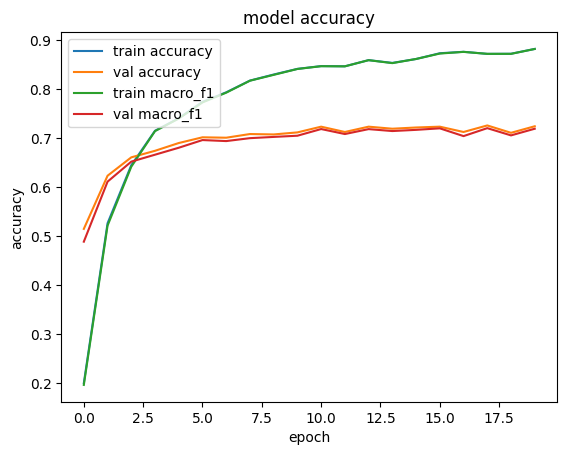

In [32]:
# Get model
model = build_model(0.4, 1e-3)
epochs = 20

# After a laptop crash, it was deemed necessary to log backups.
# The following code has been offered by Claude after the prompt:
#   If my vscode closes and I restart the training, does it continue from where it stopped?
#   If not, is there a way to make it do that?
from keras import callbacks
backup = callbacks.BackupAndRestore(backup_dir="./checkpoints/effnet_backup")
log = callbacks.CSVLogger("./checkpoints/effnet_history.csv", append=True)
best = callbacks.ModelCheckpoint("./checkpoints/effnet_best.keras",
                                 monitor="val_accuracy", save_best_only=True)


# To allow f1_scores to be used
def one_hot(ds):
    return ds.map(lambda x, y: (x, tf.one_hot(y, NUM_CLASSES)))

hist = model.fit(
    one_hot(train_ds),
    epochs=epochs,
    validation_data=one_hot(val_ds),
    callbacks=[backup, log, best]
)

plot_hist(hist)

In [35]:
# The following testing code has been taken from Claude (lightly edited).
# Claude was asked to explain how to test the model given our test_ds is
# a generator and not the entire dataset loaded into memory itself.

import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from keras.models import load_model
from keras import Model

# Load the best model (if using ModelCheckpoint in previous cell)
# print("== Loading Best Model ==")
# model: Model = load_model("./checkpoints/effnet_best.keras") # type: ignore
# print("=> Loaded Best Model\n")

y_preds, y_true = [], []
for x, y in test_ds:
    y_preds.append(model.predict_on_batch(x))
    y_true.append(np.array(y))
y_preds = np.concatenate(y_preds).argmax(1)
y_true = np.concatenate(y_true)

print(f"=> Model accuracy (test set): {accuracy_score(y_true, y_preds) * 100:.4f}%")
print(f"=> Model accuracy (test set): {f1_score(y_true, y_preds, average="macro"):.4f}")

=> Model accuracy (test set): 73.5761%
=> Model accuracy (test set): 0.7346


After multiple tests, it seems that, predictably, the model generalises better with a slower learning rate and higher dropout rate.

| Metric | Final Result |
|--------|--------------|
| Test Accuracy | 73.6% |
| F1 Score (Macro) | 0.735 |